# 07 - More features from the first 100 cycles

Stage 2 used one number per cell, log10(var(ΔQ)). The paper's bigger models also use simple values from the per-cycle summary. This notebook adds five of them, all taken from cycles 2 to 100 only:

| Feature | What it is |
|---|---|
| `q2` | discharge capacity at cycle 2 |
| `q_max_minus_q2` | highest capacity in cycles 2 to 100, minus the capacity at cycle 2 (capacity rises a little at first, see notebook 05) |
| `ir_change` | internal resistance at cycle 100 minus cycle 2 |
| `charge_time_first5` | average charge time over cycles 2 to 6 |
| `t_avg_mean` | average of the per-cycle mean temperature over cycles 2 to 100 |

The paper uses the integral of temperature over time. The summary only has a minimum, mean and maximum temperature per cycle, so `t_avg_mean` is the closest simple version.

Cycle 1 is skipped because it is empty in batch 1. The glitches at cycles 12 and 13 (notebook 04) don't matter here: the features either read single cycles that have no missing values (2 to 6 and 100) or use `max` and `mean`, which skip missing values.

As before, only the training cells are used to look at the features.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.features import summary_features

cells = pd.read_csv("../data/features_stage2.csv", index_col="cell_id")
cycles = pd.read_parquet("../data/cycles_clean.parquet")

In [2]:
feats = summary_features(cycles, last=100)
data = cells.join(feats)
data["log_life"] = np.log10(data["cycle_life"])
print(data.shape, "| missing values:", int(data.isna().sum().sum()))
data.head()

(124, 9) | missing values: 0


,split,cycle_life,log_var,q2,q_max_minus_q2,ir_change,charge_time_first5,t_avg_mean,log_life
cell_id,,,,,,,,,
b1c0,test_primary,1852.0,-5.014861,1.070689,0.006393,-0.000075,13.374894,31.603747,3.267641
b1c1,train,2160.0,-5.013960,1.075301,0.009288,-0.000042,13.409150,31.330314,3.334454
b1c2,test_primary,2237.0,-4.737000,1.079922,0.008131,-0.000014,13.358242,31.479584,3.349666
b1c3,train,1434.0,-4.442613,1.079723,0.006530,0.000039,12.025140,29.942199,3.156549
b1c4,test_primary,1709.0,-4.647744,1.078417,0.005900,-0.000053,12.041851,31.448884,3.232742


In [3]:
FEATURES = ["log_var", "q2", "q_max_minus_q2", "ir_change", "charge_time_first5", "t_avg_mean"]
train = data[data["split"] == "train"]
train[FEATURES].describe().round(4).T

,count,mean,std,min,25%,50%,75%,max
log_var,41.0,-3.6578,0.3737,-5.0140,-3.8135,-3.6199,-3.4391,-2.7457
q2,41.0,1.0743,0.0083,1.0480,1.0705,1.0745,1.0791,1.0939
q_max_minus_q2,41.0,0.0054,0.0020,0.0016,0.0038,0.0049,0.0068,0.0111
ir_change,41.0,-0.0002,0.0003,-0.0010,-0.0003,-0.0000,0.0001,0.0002
charge_time_first5,41.0,10.5297,0.8063,8.9647,10.1216,10.1474,10.7977,13.4092
t_avg_mean,41.0,32.5206,1.0050,29.8071,32.0469,32.7593,33.1564,33.7738


## How each feature relates to lifetime (training cells)

In [4]:
corr = train[FEATURES + ["log_life"]].corr()
corr["log_life"].drop("log_life").round(2).sort_values()

log_var              -0.90
t_avg_mean           -0.06
q_max_minus_q2        0.15
q2                    0.33
ir_change             0.38
charge_time_first5    0.77
Name: log_life, dtype: float64

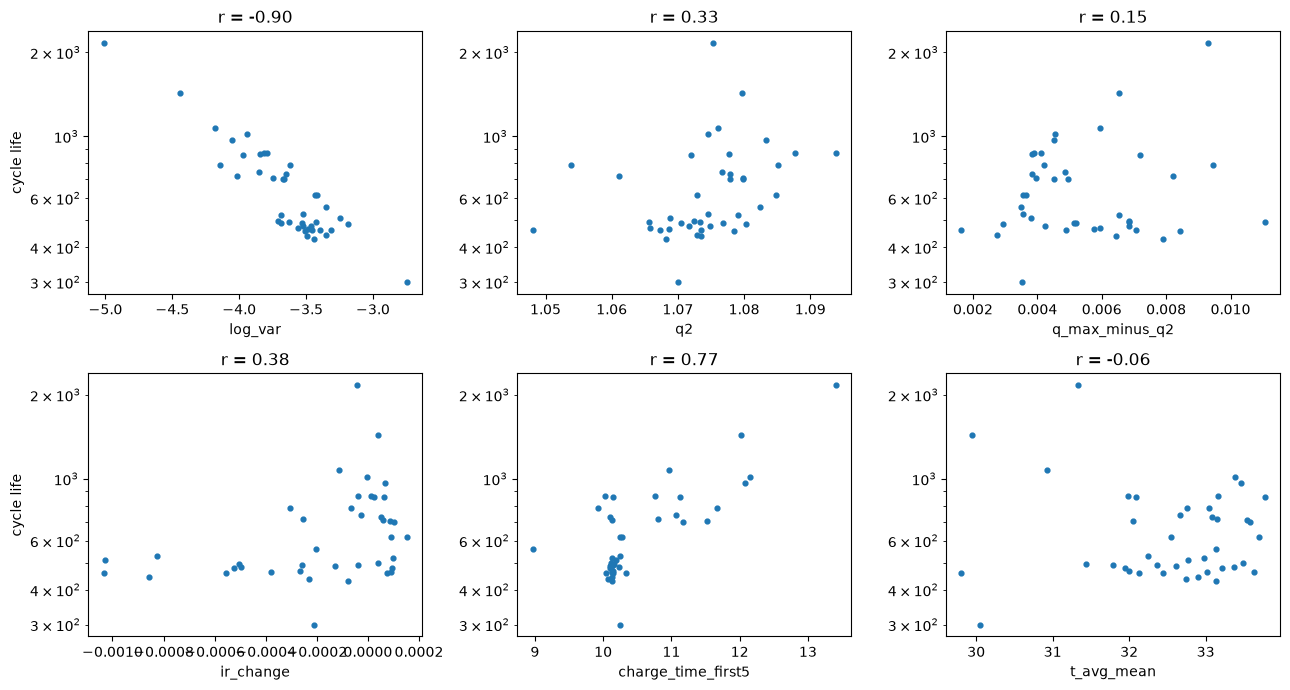

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    ax.scatter(train[col], train["cycle_life"], s=12)
    ax.set_yscale("log")
    ax.set_xlabel(col)
    ax.set_title(f"r = {corr.loc[col, 'log_life']:.2f}")
for ax in axes[:, 0]:
    ax.set_ylabel("cycle life")
plt.tight_layout()
plt.savefig("../reports/figures/features_vs_life_train.png", dpi=120)
plt.show()

## Do the new features repeat what log_var already says?

In [6]:
corr.loc[FEATURES, FEATURES].round(2)

,log_var,q2,q_max_minus_q2,ir_change,charge_time_first5,t_avg_mean
log_var,1.00,-0.12,-0.43,-0.37,-0.77,0.11
q2,-0.12,1.00,-0.27,0.54,-0.00,0.11
q_max_minus_q2,-0.43,-0.27,1.00,0.25,0.24,-0.23
ir_change,-0.37,0.54,0.25,1.00,0.24,0.11
charge_time_first5,-0.77,-0.00,0.24,0.24,1.00,-0.13
t_avg_mean,0.11,0.11,-0.23,0.11,-0.13,1.00


## Two things in the scatter plots worth checking

Charge time has the strongest link after log_var, but most cells sit around 10 minutes and a small group charges much slower. And for resistance, a few cells drop clearly while most barely change.

In [7]:
slow = train[train["charge_time_first5"] > 11]
others = train.drop(index=slow.index)
r_others = np.corrcoef(others["charge_time_first5"], others["log_life"])[0, 1]
print(len(slow), "training cells charge slower than 11 min:", slow.index.tolist())
print(f"charge time vs log life for the other {len(others)} cells: r = {r_others:.2f}")

drop = train[train["ir_change"] < -0.0005]
print(f"median resistance change on training cells: {train['ir_change'].median() * 1000:.3f} mOhm")
print(len(drop), "cells lose more than 0.5 mOhm; their lives:", sorted(drop["cycle_life"].astype(int).tolist()))

9 training cells charge slower than 11 min: ['b1c1', 'b1c3', 'b1c11', 'b1c24', 'b1c28', 'b1c34', 'b1c36', 'b1c40', 'b1c42']
charge time vs log life for the other 32 cells: r = 0.31
median resistance change on training cells: -0.042 mOhm
7 cells lose more than 0.5 mOhm; their lives: [444, 461, 461, 477, 494, 511, 527]


## Save

In [8]:
data[["split", "cycle_life"] + FEATURES].to_csv("../data/features_stage3.csv")
print("saved", len(data), "rows,", len(FEATURES), "features")

saved 124 rows, 6 features


## Notes

- All five features exist for all 124 cells, with no missing values.
- Their correlation with log10(cycle life) on the training cells: charge time 0.77, resistance change 0.38, capacity at cycle 2 0.33, capacity rise 0.15, mean temperature -0.06. None gets close to log_var (-0.90).
- Charge time looks strong mostly because of 9 batch 1 cells that charge in more than 11 minutes and live long. Among the other 32 cells it drops to 0.31. Charge time is mostly set by the charging policy: slower charging, longer life. The lab knows the policy before the test starts, so the feature is fair to use, but it says more about the policy than about how the cell is ageing. It also correlates with log_var (-0.77), so part of what it says is already covered.
- Resistance barely moves in the first 100 cycles for most cells (median change -0.04 mOhm). The 7 cells that lose more than 0.5 mOhm all live between 444 and 527 cycles, so a clear drop seems to go with a short life.
- Capacity at cycle 2 and the early capacity rise are weak on their own, and mean temperature shows nothing. They might still help next to log_var, or just add noise.
- Correlations only show which features might help. Whether any of them improves on log_var alone is decided in step 3.3, with cross-validation on the training cells.